In [17]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [ ]:

np.random.seed(42)

n = 500

study_hours = np.random.uniform(1, 8, n)
attendance = np.random.uniform(50, 100, n)
previous_marks = np.random.uniform(30, 95, n)
assignment_score = np.random.uniform(35, 100, n)
sleep_hours = np.random.uniform(4, 9, n)

# Generate simulated final marks
noise = np.random.normal(0, 5, n)

final_marks = (
    5
    + 3.5 * study_hours
    + 0.20 * attendance
    + 0.30 * previous_marks
    + 0.15 * assignment_score
    + 0.8 * sleep_hours
    + noise
)

# Keep marks between 0 and 100
final_marks = np.clip(final_marks, 0, 100)

df = pd.DataFrame({
    "Study_Hours": study_hours.round(1),
    "Attendance": attendance.round(1),
    "Previous_Marks": previous_marks.round(1),
    "Assignment_Score": assignment_score.round(1),
    "Sleep_Hours": sleep_hours.round(1),
    "Final_Marks": final_marks.round(1)
})

# Save the dataset
df.to_csv("student_performance.csv", index=False)

print("Dataset created successfully!")
print("Number of student records:", len(df))

df.head(10)


Dataset created successfully!
Number of student records: 500


,Study_Hours,Attendance,Previous_Marks,Assignment_Score,Sleep_Hours,Final_Marks
0,3.6,84.9,42.0,68.7,5.3,64.4
1,7.7,76.8,65.2,66.1,5.2,84.1
2,6.1,65.5,86.7,36.7,8.5,80.7
3,5.2,90.7,77.6,57.2,5.2,77.8
4,2.1,84.2,82.4,59.7,5.4,66.2
5,2.1,58.1,72.8,60.9,7.8,60.4
6,1.4,95.5,75.0,72.7,6.2,66.5
7,7.1,91.1,85.2,69.7,7.9,95.9
8,5.2,97.5,46.2,74.5,4.3,74.2
9,6.0,86.3,61.8,84.7,6.4,64.8


In [ ]:

print("Dataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nFirst five records:")
display(df.head())

print("\nStatistical summary:")
display(df.describe())


Dataset shape:
(500, 6)

Column names:
['Study_Hours', 'Attendance', 'Previous_Marks', 'Assignment_Score', 'Sleep_Hours', 'Final_Marks']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Study_Hours       500 non-null    float64
 1   Attendance        500 non-null    float64
 2   Previous_Marks    500 non-null    float64
 3   Assignment_Score  500 non-null    float64
 4   Sleep_Hours       500 non-null    float64
 5   Final_Marks       500 non-null    float64
dtypes: float64(6)
memory usage: 23.6 KB

First five records:


,Study_Hours,Attendance,Previous_Marks,Assignment_Score,Sleep_Hours,Final_Marks
0,3.6,84.9,42.0,68.7,5.3,64.4
1,7.7,76.8,65.2,66.1,5.2,84.1
2,6.1,65.5,86.7,36.7,8.5,80.7
3,5.2,90.7,77.6,57.2,5.2,77.8
4,2.1,84.2,82.4,59.7,5.4,66.2



Statistical summary:


,Study_Hours,Attendance,Previous_Marks,Assignment_Score,Sleep_Hours,Final_Marks
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,4.489800,74.095400,63.642200,67.271000,6.500000,69.873800
std,2.090199,14.274176,19.316579,18.656599,1.428987,11.396581
min,1.000000,50.200000,30.300000,35.200000,4.000000,39.600000
25%,2.700000,61.475000,45.650000,50.675000,5.375000,62.200000
50%,4.600000,73.600000,65.100000,68.050000,6.500000,69.600000
75%,6.300000,86.325000,80.550000,82.900000,7.700000,77.325000
max,8.000000,100.000000,95.000000,99.900000,9.000000,99.000000


In [ ]:

print("Missing values before cleaning:")
print(df.isnull().sum())

# Fill missing numeric values with the column median
df = df.fillna(df.median(numeric_only=True))

print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

# Remove duplicate records if any
df = df.drop_duplicates().reset_index(drop=True)

print("Dataset cleaned successfully!")


Missing values before cleaning:
Study_Hours         0
Attendance          0
Previous_Marks      0
Assignment_Score    0
Sleep_Hours         0
Final_Marks         0
dtype: int64

Missing values after cleaning:
Study_Hours         0
Attendance          0
Previous_Marks      0
Assignment_Score    0
Sleep_Hours         0
Final_Marks         0
dtype: int64

Duplicate rows: 0
Dataset cleaned successfully!


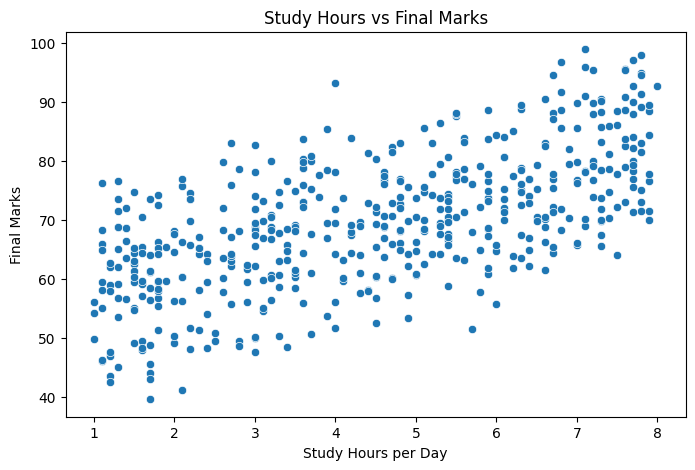

In [ ]:

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Study_Hours",
    y="Final_Marks"
)

plt.title("Study Hours vs Final Marks")
plt.xlabel("Study Hours per Day")
plt.ylabel("Final Marks")
plt.show()


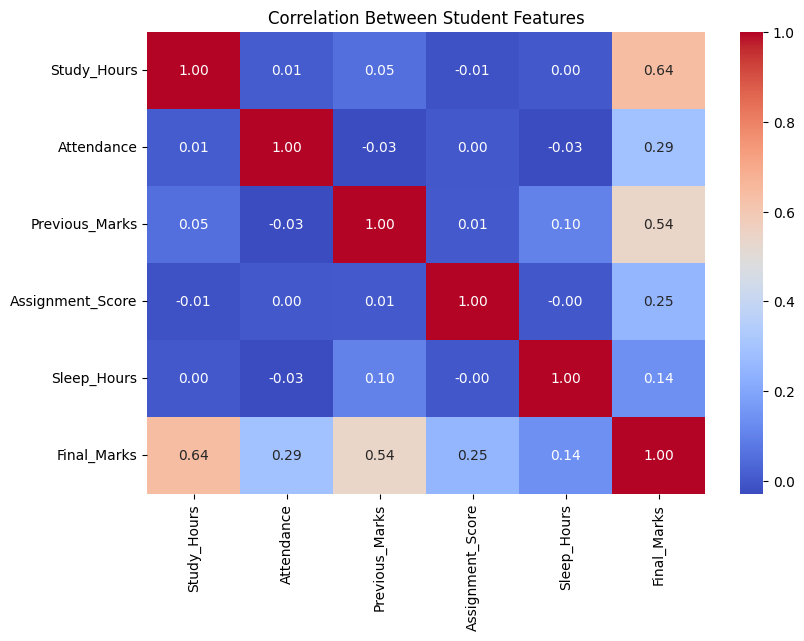

In [ ]:

plt.figure(figsize=(9, 6))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Student Features")
plt.show()


In [ ]:

# Input features
X = df[
    [
        "Study_Hours",
        "Attendance",
        "Previous_Marks",
        "Assignment_Score",
        "Sleep_Hours"
    ]
]

# Target variable
y = df["Final_Marks"]

print("Input features shape:", X.shape)
print("Target variable shape:", y.shape)


Input features shape: (500, 5)
Target variable shape: (500,)


In [8]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 400
Testing records: 100


In [12]:
# Initialize and train models
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
lr_predictions = lr_model.predict(X_test)

rf_model = RandomForestRegressor(random_state=42)
rf_model.fit(X_train, y_train)
rf_predictions = rf_model.predict(X_test)

def evaluate_model(name, actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)

    return {
        "Model": name,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "R2 Score": round(r2, 4)
    }

# Construct evaluation DataFrame
results = pd.DataFrame([
    evaluate_model("Linear Regression", y_test, lr_predictions),
    evaluate_model("Random Forest", y_test, rf_predictions)
])

display(results)

# Select the model with the lower RMSE
best_name = results.loc[results["RMSE"].idxmin(), "Model"]

if best_name == "Linear Regression":
    best_model = lr_model
else:
    best_model = rf_model

print("Model with lower test RMSE:", best_name)

,Model,MAE,RMSE,R2 Score
0,Linear Regression,3.67,4.72,0.8016
1,Random Forest,4.43,5.59,0.7208


Model with lower test RMSE: Linear Regression


Feature Importance:


,Importance
Study_Hours,0.455868
Previous_Marks,0.314594
Attendance,0.108787
Assignment_Score,0.083815
Sleep_Hours,0.036935


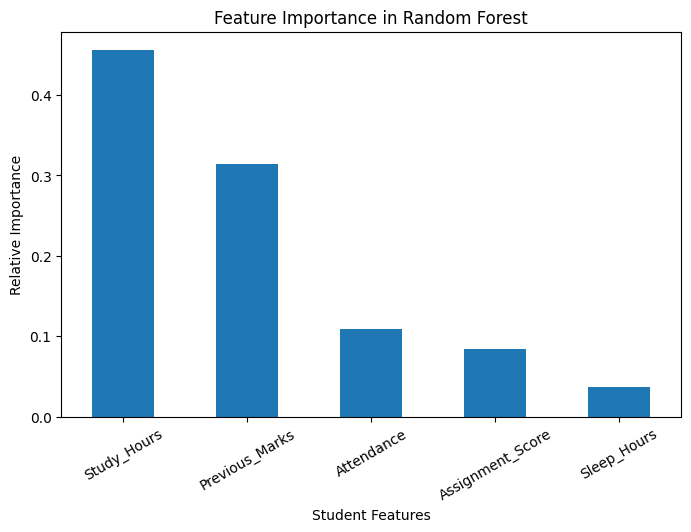

In [14]:

importance = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("Feature Importance:")
display(importance.to_frame("Importance"))

importance.plot(kind="bar", figsize=(8, 5))
plt.title("Feature Importance in Random Forest")
plt.xlabel("Student Features")
plt.ylabel("Relative Importance")
plt.xticks(rotation=30)
plt.show()


In [15]:

from google.colab import files
import joblib

# Download the dataset
df.to_csv("student_performance.csv", index=False)
files.download("student_performance.csv")

# Save the best model and its feature names
joblib.dump(
    {
        "model": best_model,
        "features": list(X.columns)
    },
    "student_performance_model.pkl"
)

print("Trained model saved successfully!")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Trained model saved successfully!


In [16]:

files.download("student_performance_model.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>